In [1]:
import os
import sys
sys.path.append("./models")
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import cv2
from PIL import Image

import torch
import torch.nn.functional as F

from llava.constants import IMAGE_TOKEN_INDEX, DEFAULT_IMAGE_TOKEN, DEFAULT_IM_START_TOKEN, DEFAULT_IM_END_TOKEN
from llava.conversation import conv_templates, SeparatorStyle
from llava.model.builder import load_pretrained_model
from llava.utils import disable_torch_init
from llava.mm_utils import process_images, tokenizer_image_token, get_model_name_from_path

from utils import (
    load_image, 
    aggregate_llm_attention, aggregate_vit_attention,
    heterogenous_stack,
    show_mask_on_image
)

ModuleNotFoundError: No module named 'cv2'

In [ ]:
# ===> specify the model path
model_path = "liuhaotian/llava-v1.5-7b"

# load the model
load_8bit = False
load_4bit = False
device = "cuda" if torch.cuda.is_available() else "cpu"

disable_torch_init()

model_name = get_model_name_from_path(model_path)
tokenizer, model, image_processor, context_len = load_pretrained_model(
    model_path, 
    None, # model_base
    model_name, 
    load_8bit, 
    load_4bit, 
    device=device
)

You are using a model of type llava to instantiate a model of type llava_llama. This is not supported for all configurations of models and can yield errors.
Loading checkpoint shards:   0%|                                                                      | 0/2 [00:00<?, ?it/s]/home/model_editing/data/miniconda3/envs/acv_env/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
Loading checkpoint shards: 100%|██████████████████████████████████████████████████████████████| 2/2 [00:30<00:00, 15.10s/it]


In [ ]:
!pwd

/home/model_editing/acv_project/VLM-Visualizer


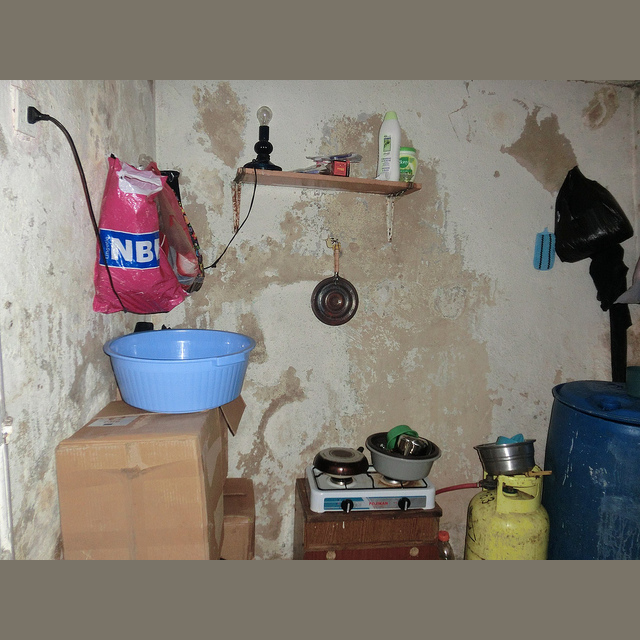

Give a detailed description of the image.


In [ ]:
# ===> specify the image path or url and the prompt text
# image_path_or_url = "../HalTrapper_no_virgin/playground/dining_table.jpg"
image_path_or_url = "../../data/datasets/coco/coco/val2014/COCO_val2014_000000332908.jpg"
# prompt_text = "What fruits do you observe on the table?"
prompt_text = "Give a detailed description of the image."

################################################
# preparation for the generation
# unlikely that you need to change anything here
if "llama-2" in model_name.lower():
    conv_mode = "llava_llama_2"
elif "mistral" in model_name.lower():
    conv_mode = "mistral_instruct"
elif "v1.6-34b" in model_name.lower():
    conv_mode = "chatml_direct"
elif "v1" in model_name.lower():
    conv_mode = "llava_v1"
elif "mpt" in model_name.lower():
    conv_mode = "mpt"
else:
    conv_mode = "llava_v0"

conv = conv_templates[conv_mode].copy()
if "mpt" in model_name.lower():
    roles = ('user', 'assistant')
else:
    roles = conv.roles

image = load_image(image_path_or_url)
image_tensor, images = process_images([image], image_processor, model.config)
image = images[0]
image_size = image.size
if type(image_tensor) is list:
    image_tensor = [image.to(model.device, dtype=torch.float16) for image in image_tensor]
else:
    image_tensor = image_tensor.to(model.device, dtype=torch.float16)

if model.config.mm_use_im_start_end:
    inp = DEFAULT_IM_START_TOKEN + DEFAULT_IMAGE_TOKEN + DEFAULT_IM_END_TOKEN + '\n' + prompt_text
else:
    inp = DEFAULT_IMAGE_TOKEN + '\n' + prompt_text

conv.append_message(conv.roles[0], inp)
conv.append_message(conv.roles[1], None)
prompt = conv.get_prompt()
# manually removing the system prompt here
# otherwise most attention will be somehow put on the system prompt
prompt = prompt.replace(
    "A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions. ",
    ""
)

input_ids = tokenizer_image_token(prompt, tokenizer, IMAGE_TOKEN_INDEX, return_tensors='pt').unsqueeze(0).to(model.device)
################################################

display(image)
print(prompt_text)

In [ ]:
# generate the response
with torch.inference_mode():
    outputs = model.generate(
        input_ids,
        images=image_tensor,
        image_sizes=[image_size],
        do_sample=False,
        max_new_tokens=512,
        use_cache=False,
        return_dict_in_generate=True,
        output_attentions=True,
    )

text = tokenizer.decode(outputs["sequences"][0]).strip()
print(text)

The image shows a room with a variety of items, including a blue bowl, a bottle, a bowl, a box, a bag, and a bowl. There is also a sink in the room. The room appears to be a mix of a kitchen and a living space, with a variety of objects scattered throughout.</s>


Below we are aggregating LLM's attention aross heads and layers (simply averaging them). See the `aggregate_llm_attention` in `utils.py` for details. 

In [ ]:
# constructing the llm attention matrix
aggregated_prompt_attention = []
for i, layer in enumerate(outputs["attentions"][0]):
    layer_attns = layer.squeeze(0)
    attns_per_head = layer_attns.mean(dim=0)
    cur = attns_per_head[:-1].cpu().clone()
    # following the practice in `aggregate_llm_attention`
    # we are zeroing out the attention to the first <bos> token
    # for the first row `cur[0]` (corresponding to the next token after <  bos>), however,
    # we don't do this because <bos> is the only token that it can attend to
    cur[1:, 0] = 0.
    cur[1:] = cur[1:] / cur[1:].sum(-1, keepdim=True)
    aggregated_prompt_attention.append(cur)
aggregated_prompt_attention = torch.stack(aggregated_prompt_attention).mean(dim=0)

# llm_attn_matrix will be of torch.Size([N, N])
# where N is the total number of input (both image and text ones) + output tokens
llm_attn_matrix = heterogenous_stack(
    [torch.tensor([1])]
    + list(aggregated_prompt_attention) 
    + list(map(aggregate_llm_attention, outputs["attentions"]))
)

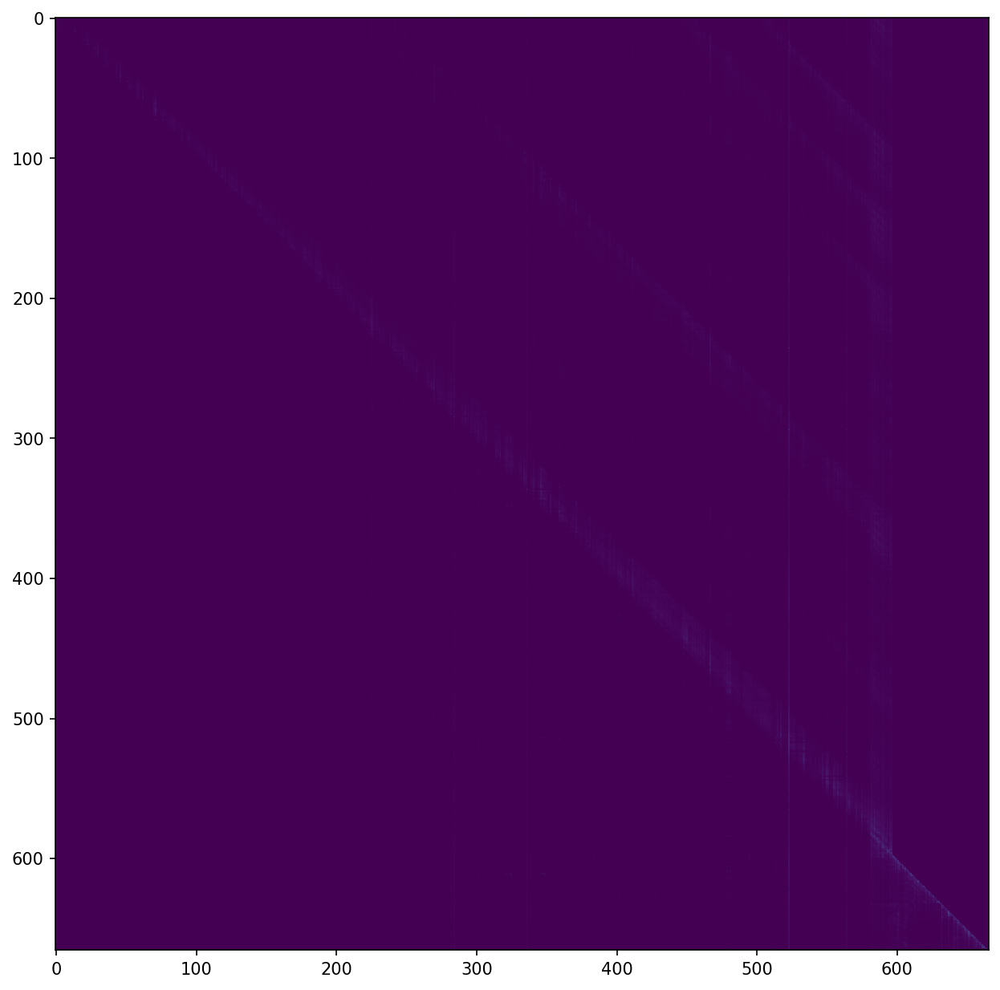

In [ ]:
# visualize the llm attention matrix
# ===> adjust the gamma factor to enhance the visualization
#      higer gamma brings out more low attention values
gamma_factor = 1
enhanced_attn_m = np.power(llm_attn_matrix.numpy(), 1 / gamma_factor)

fig, ax = plt.subplots(figsize=(10, 20), dpi=150)
ax.imshow(enhanced_attn_m, vmin=enhanced_attn_m.min(), vmax=enhanced_attn_m.max(), interpolation="nearest")

In [ ]:
# identify length or index of tokens
input_token_len = model.get_vision_tower().num_patches + len(input_ids[0]) - 1 # -1 for the <image> token
vision_token_start = len(tokenizer(prompt.split("<image>")[0], return_tensors='pt')["input_ids"][0])
vision_token_end = vision_token_start + model.get_vision_tower().num_patches
output_token_len = len(outputs["sequences"][0])
output_token_start = input_token_len
output_token_end = input_token_len + output_token_len

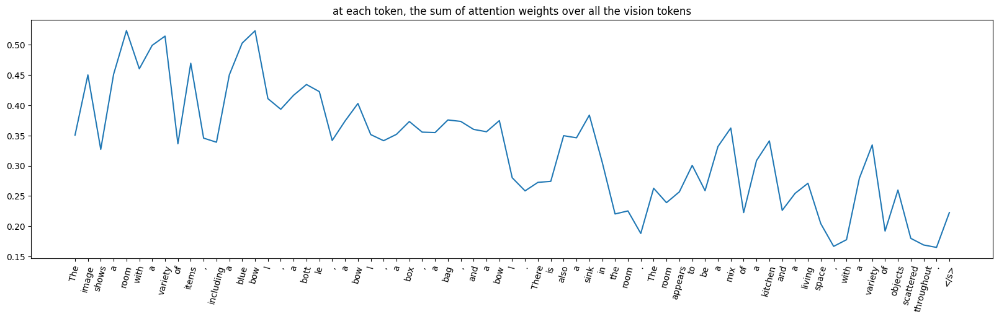

In [ ]:
# look at the attention weights over the vision tokens
overall_attn_weights_over_vis_tokens = []
for i, (row, token) in enumerate(
    zip(
        llm_attn_matrix[input_token_len:], 
        outputs["sequences"][0].tolist()
    )
):
    # print(
    #     i + input_token_len, 
    #     f"{tokenizer.decode(token, add_special_tokens=False).strip():<15}", 
    #     f"{row[vision_token_start:vision_token_end].sum().item():.4f}"
    # )

    overall_attn_weights_over_vis_tokens.append(
        row[vision_token_start:vision_token_end].sum().item()
    )

# plot the trend of attention weights over the vision tokens
fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(overall_attn_weights_over_vis_tokens)
ax.set_xticks(range(len(overall_attn_weights_over_vis_tokens)))
ax.set_xticklabels(
    [tokenizer.decode(token, add_special_tokens=False).strip() for token in outputs["sequences"][0].tolist()],
    rotation=75
)
ax.set_title("at each token, the sum of attention weights over all the vision tokens");

Below we aim to visualize the attention w.r.t. the input image. First we obtain a single attention map from the vision encoder (ViT) by again averaging the attention maps across heads and layers. I have tried a supposedly more reasonable method of [attention rollout](https://github.com/jacobgil/vit-explain/blob/main/vit_rollout.py), i.e. multiplying the attention matrices over each layer, but never got sensible results. See the `aggregate_vit_attention` in `utils.py` for details.


Then, for each generated token of LLM, we compute the weighted average of the attention map of each vision token to get an aggregated attention map over the input image for that generated token. Finally we resize and overlay the attention map on the input image.

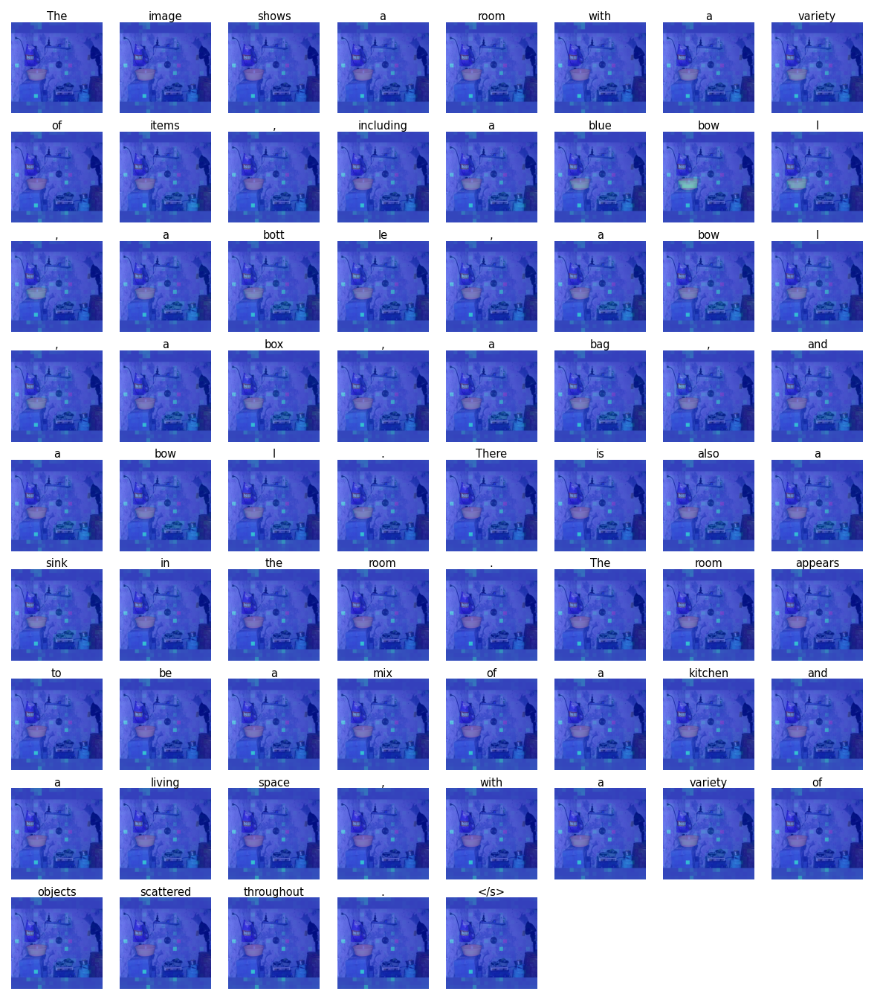

In [ ]:
# connect with the vision encoder attention
# to visualize the attention over the image

# vis_attn_matrix will be of torch.Size([N, N])
# where N is the number of vision tokens/patches
# `all_prev_layers=True` will average attention from all layers until the selected layer
# otherwise only the selected layer's attention will be used
vis_attn_matrix = aggregate_vit_attention(
    model.get_vision_tower().image_attentions,
    select_layer=model.get_vision_tower().select_layer,
    all_prev_layers=True
)
grid_size = model.get_vision_tower().num_patches_per_side

num_image_per_row = 8
image_ratio = image_size[0] / image_size[1]
num_rows = output_token_len // num_image_per_row + (1 if output_token_len % num_image_per_row != 0 else 0)
fig, axes = plt.subplots(
    num_rows, num_image_per_row, 
    figsize=(10, (10 / num_image_per_row) * image_ratio * num_rows), 
    dpi=150
)
plt.subplots_adjust(wspace=0.05, hspace=0.2)

# whether visualize the attention heatmap or 
# the image with the attention heatmap overlayed
vis_overlayed_with_attn = True

output_token_inds = list(range(output_token_start, output_token_end))
for i, ax in enumerate(axes.flatten()):
    if i >= output_token_len:
        ax.axis("off")
        continue

    target_token_ind = output_token_inds[i]
    attn_weights_over_vis_tokens = llm_attn_matrix[target_token_ind][vision_token_start:vision_token_end]
    attn_weights_over_vis_tokens = attn_weights_over_vis_tokens / attn_weights_over_vis_tokens.sum()

    attn_over_image = []
    for weight, vis_attn in zip(attn_weights_over_vis_tokens, vis_attn_matrix):
        vis_attn = vis_attn.reshape(grid_size, grid_size)
        # vis_attn = vis_attn / vis_attn.max()
        attn_over_image.append(vis_attn * weight)
    attn_over_image = torch.stack(attn_over_image).sum(dim=0)
    attn_over_image = attn_over_image / attn_over_image.max()

    attn_over_image = F.interpolate(
        attn_over_image.unsqueeze(0).unsqueeze(0), 
        size=image.size, 
        mode='nearest', 
        # mode='bicubic', align_corners=False
    ).squeeze()

    np_img = np.array(image)[:, :, ::-1]
    img_with_attn, heatmap = show_mask_on_image(np_img, attn_over_image.numpy())
    ax.imshow(heatmap if not vis_overlayed_with_attn else img_with_attn)
    ax.set_title(
        tokenizer.decode(outputs["sequences"][0][i], add_special_tokens=False).strip(),
        fontsize=7,
        pad=1
    )
    ax.axis("off");

Visualizing attention for word: 'sink' (Occurrence: 1)
Mapped to token: 'sink'


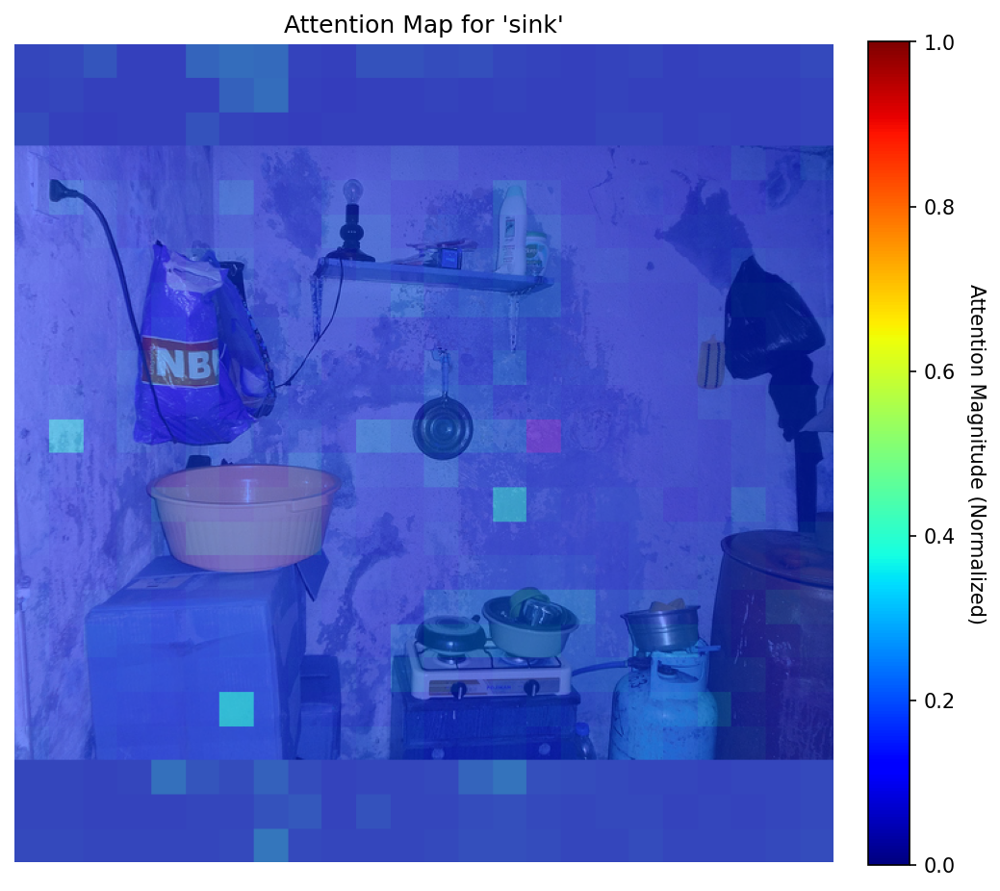

In [ ]:
import re
import matplotlib.cm as cm
import matplotlib.pyplot as plt

# ==========================================
# USER CONFIGURATION
# ==========================================
target_word = "sink"   # The word you want to visualize
nth_occurrence = 1      # 1 for the first occurrence, 2 for the second, etc.
# ==========================================

# 1. Get the generated tokens and full text
# We slice outputs["sequences"] using the length of the *input IDs* (prompt)
# to isolate just the generated tokens.

# get the full sequence including prompt
full_sequence = outputs["sequences"][0]
prompt_token_len = len(input_ids[0])

# # check if we have generated tokens
# if len(full_sequence) <= prompt_token_len:
#     print(f"Error: No new tokens generated. Sequence length: {len(full_sequence)}, Prompt length: {prompt_token_len}")
#     print(f"Using full sequence instead.")
#     generated_tokens = full_sequence  # use full sequence as fallback
#     prompt_token_len = 0  # adjust accordingly
# else:
generated_tokens = full_sequence

full_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)

# 2. Find the character index of the target word
matches = list(re.finditer(re.escape(target_word), full_text, re.IGNORECASE))

if len(matches) < nth_occurrence:
    print(f"Error: The word '{target_word}' was not found {nth_occurrence} times in the output.")
    print(f"Full generated text: '{full_text}'")
else:
    # Get start char index of the Nth occurrence
    char_start_idx = matches[nth_occurrence - 1].start()
    
    # 3. Map the character index back to the correct token
    # We reconstruct the string token-by-token to find where the word starts
    target_token_relative_idx = -1
    
    for i in range(len(generated_tokens)):
        # Decode up to token i+1 to check length
        text_chunk = tokenizer.decode(generated_tokens[:i+1], skip_special_tokens=True)
        
        # If this chunk is long enough to contain the start of our word,
        # then token 'i' is the first token of that word.
        if len(text_chunk) > char_start_idx:
            target_token_relative_idx = i
            break

    if target_token_relative_idx != -1:
        # 4. Calculate global attention index
        # output_token_start is the index in the attention matrix (includes image patches)
        target_token_global_ind = output_token_start + target_token_relative_idx
        
        print(f"Visualizing attention for word: '{target_word}' (Occurrence: {nth_occurrence})")
        print(f"Mapped to token: '{tokenizer.decode(generated_tokens[target_token_relative_idx])}'")

        # 5. Extract and Aggregate Attention
        # Get attention weights from LLM for this token over the vision tokens
        attn_weights_over_vis_tokens = llm_attn_matrix[target_token_global_ind][vision_token_start:vision_token_end]
        attn_weights_over_vis_tokens = attn_weights_over_vis_tokens / attn_weights_over_vis_tokens.sum()

        # Weighted sum of vision attention maps
        attn_over_image = []
        for weight, vis_attn in zip(attn_weights_over_vis_tokens, vis_attn_matrix):
            vis_attn = vis_attn.reshape(grid_size, grid_size)
            attn_over_image.append(vis_attn * weight)
        
        attn_over_image = torch.stack(attn_over_image).sum(dim=0)
        
        # Normalize to 0-1 for visualization
        attn_over_image = attn_over_image / attn_over_image.max()

        # 6. Resize and Plot with Scale
        attn_over_image = F.interpolate(
            attn_over_image.unsqueeze(0).unsqueeze(0), 
            size=image.size, 
            mode='nearest', 
        ).squeeze()

        # Generate overlay image
        np_img = np.array(image)[:, :, ::-1]
        img_with_attn, heatmap = show_mask_on_image(np_img, attn_over_image.numpy())

        # Plotting
        fig, ax = plt.subplots(figsize=(8, 8), dpi=150)
        
        # Display the overlay image
        im = ax.imshow(img_with_attn)
        
        # Create a ScalarMappable for the colorbar (using 'jet' as show_mask_on_image defaults to it)
        sm = cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=0, vmax=1))
        sm.set_array([])
        
        # Add the colorbar/scale
        cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Attention Magnitude (Normalized)', rotation=270, labelpad=15)
        
        ax.set_title(f"Attention Map for '{target_word}'")
        ax.axis("off")
        plt.show()
        
    else:
        print("Error: Could not map the word to a specific token.")

In [ ]:
from IPython.display import display, HTML
display(HTML("<style>.output_scroll {height: auto !important; max-height: none !important;}</style>"))

Total number of layers in Vision Tower: 24
Visualizing layers: [5, 10, 15, 20]

Visualizing per-head attention for word: 'sink' (Occurrence: 1)
Mapped to token: 'sink'

LAYER 5: PAIRWISE COSINE SIMILARITY BETWEEN ATTENTION HEADS
     Head 0  Head 1  Head 2  Head 3  Head 4  Head 5  Head 6  Head 7  Head 8  Head 9  Head10  Head11  Head12  Head13  Head14  Head15  
-------------------------------------------------------------------------------------------------------------------------------------
Head 0  1.000   0.546   0.221   0.618   0.745   0.480   0.517   0.690   0.699   0.718   0.756   0.428   0.693   0.428   0.616   0.607  
Head 1  0.546   1.000   0.764   0.872   0.736   0.779   0.758   0.697   0.674   0.800   0.662   0.648   0.519   0.460   0.632   0.632  
Head 2  0.221   0.764   1.000   0.739   0.546   0.815   0.645   0.510   0.489   0.630   0.430   0.665   0.248   0.347   0.526   0.459  
Head 3  0.618   0.872   0.739   1.000   0.819   0.795   0.794   0.757   0.718   0.806   0.717  

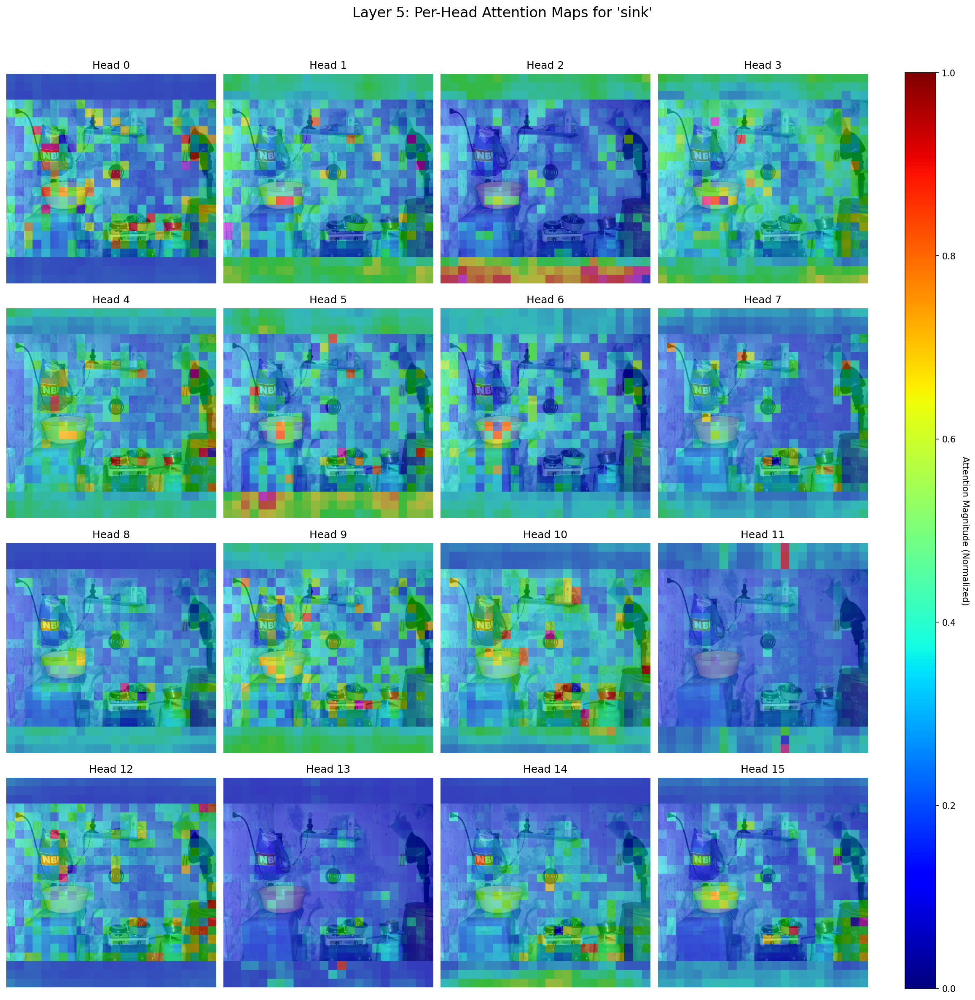

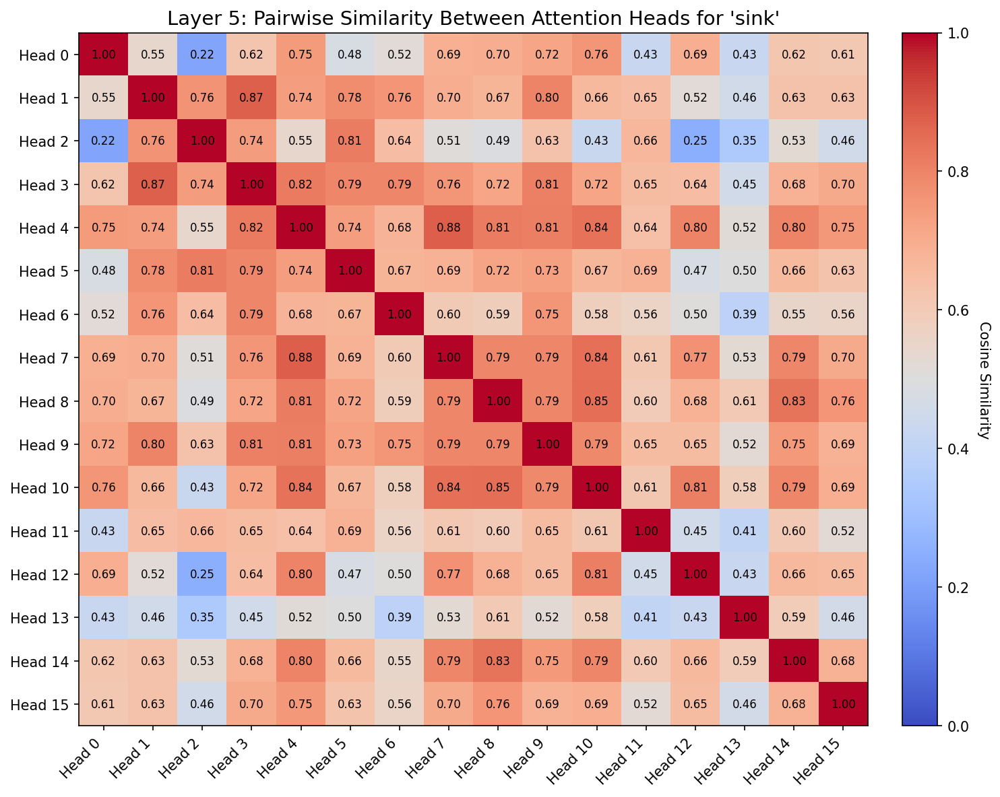


LAYER 10: PAIRWISE COSINE SIMILARITY BETWEEN ATTENTION HEADS
     Head 0  Head 1  Head 2  Head 3  Head 4  Head 5  Head 6  Head 7  Head 8  Head 9  Head10  Head11  Head12  Head13  Head14  Head15  
-------------------------------------------------------------------------------------------------------------------------------------
Head 0  1.000   0.718   0.757   0.730   0.793   0.855   0.809   0.878   0.877   0.892   0.861   0.841   0.723   0.889   0.755   0.746  
Head 1  0.718   1.000   0.664   0.626   0.669   0.681   0.707   0.744   0.674   0.679   0.731   0.785   0.677   0.704   0.758   0.730  
Head 2  0.757   0.664   1.000   0.668   0.800   0.755   0.686   0.816   0.757   0.694   0.626   0.825   0.712   0.837   0.676   0.790  
Head 3  0.730   0.626   0.668   1.000   0.713   0.715   0.724   0.755   0.633   0.700   0.710   0.740   0.629   0.731   0.615   0.632  
Head 4  0.793   0.669   0.800   0.713   1.000   0.767   0.685   0.790   0.781   0.770   0.677   0.769   0.727   0.825   0.699 

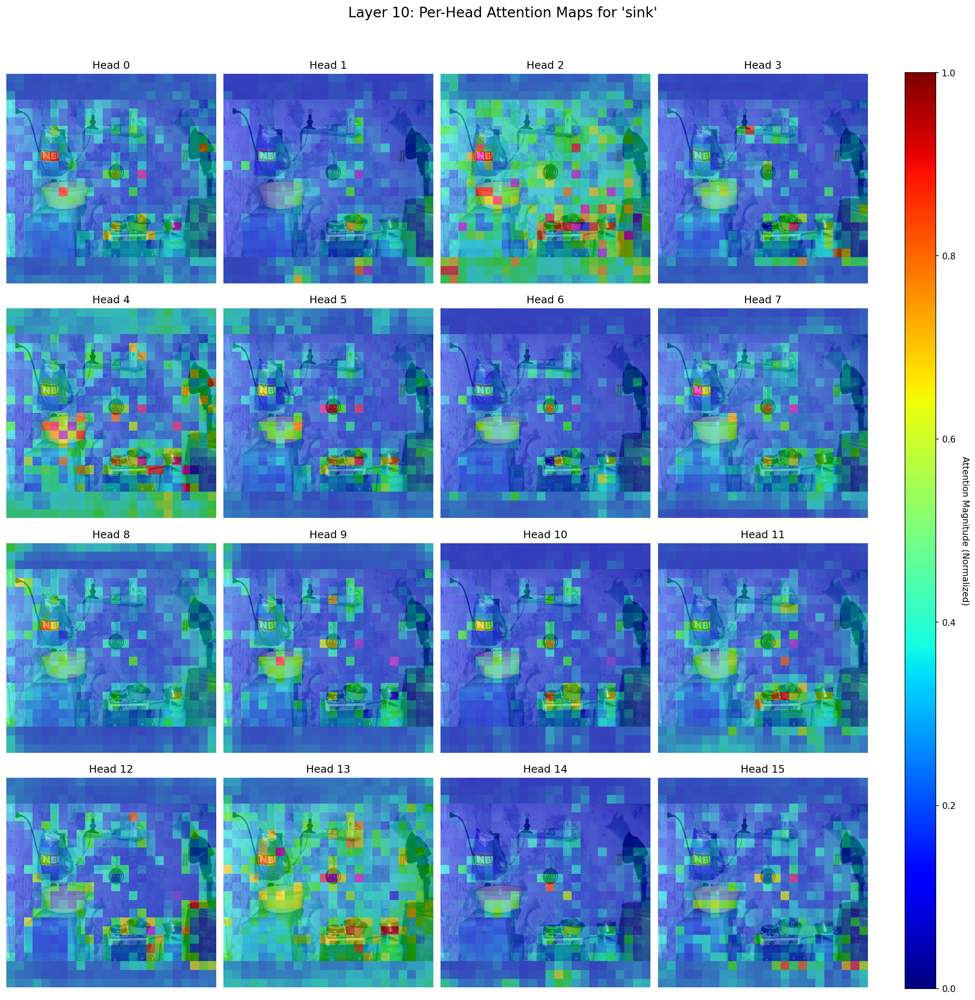

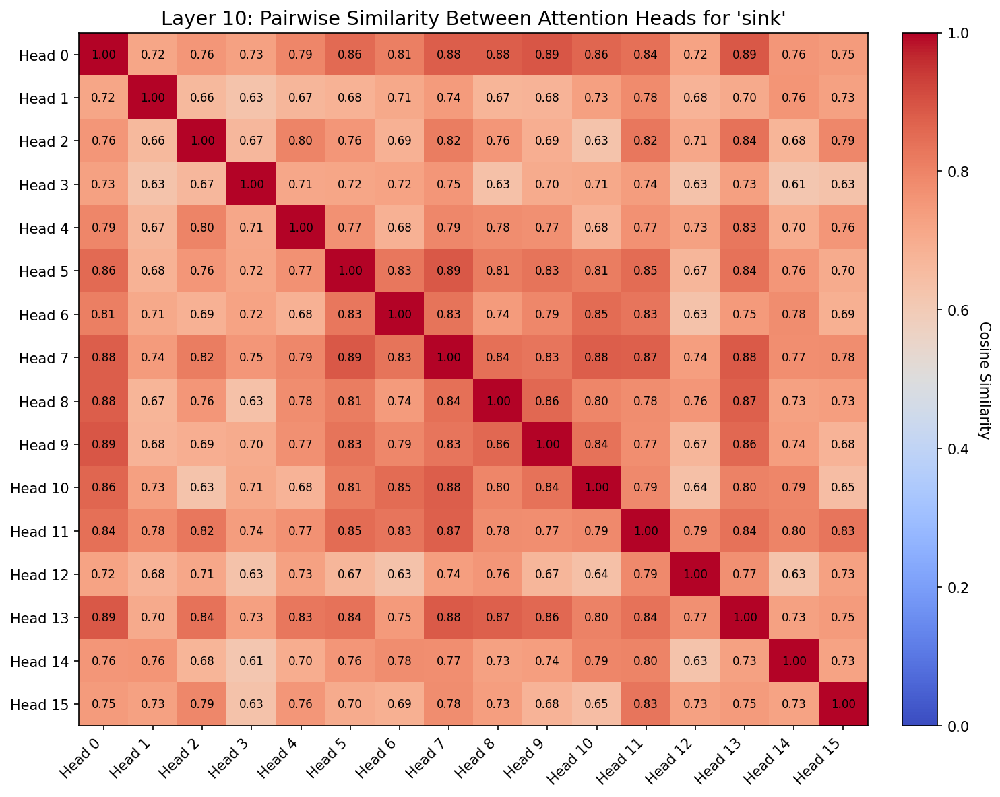


LAYER 15: PAIRWISE COSINE SIMILARITY BETWEEN ATTENTION HEADS
     Head 0  Head 1  Head 2  Head 3  Head 4  Head 5  Head 6  Head 7  Head 8  Head 9  Head10  Head11  Head12  Head13  Head14  Head15  
-------------------------------------------------------------------------------------------------------------------------------------
Head 0  1.000   0.917   0.977   0.932   0.987   0.986   0.989   0.967   0.941   0.990   0.980   0.982   0.977   0.982   0.986   0.985  
Head 1  0.917   1.000   0.919   0.902   0.876   0.869   0.900   0.889   0.933   0.902   0.894   0.952   0.901   0.928   0.915   0.906  
Head 2  0.977   0.919   1.000   0.904   0.951   0.953   0.957   0.931   0.942   0.959   0.950   0.969   0.960   0.964   0.959   0.965  
Head 3  0.932   0.902   0.904   1.000   0.922   0.921   0.939   0.929   0.910   0.936   0.939   0.935   0.934   0.935   0.942   0.933  
Head 4  0.987   0.876   0.951   0.922   1.000   0.997   0.993   0.970   0.915   0.995   0.986   0.971   0.975   0.976   0.985 

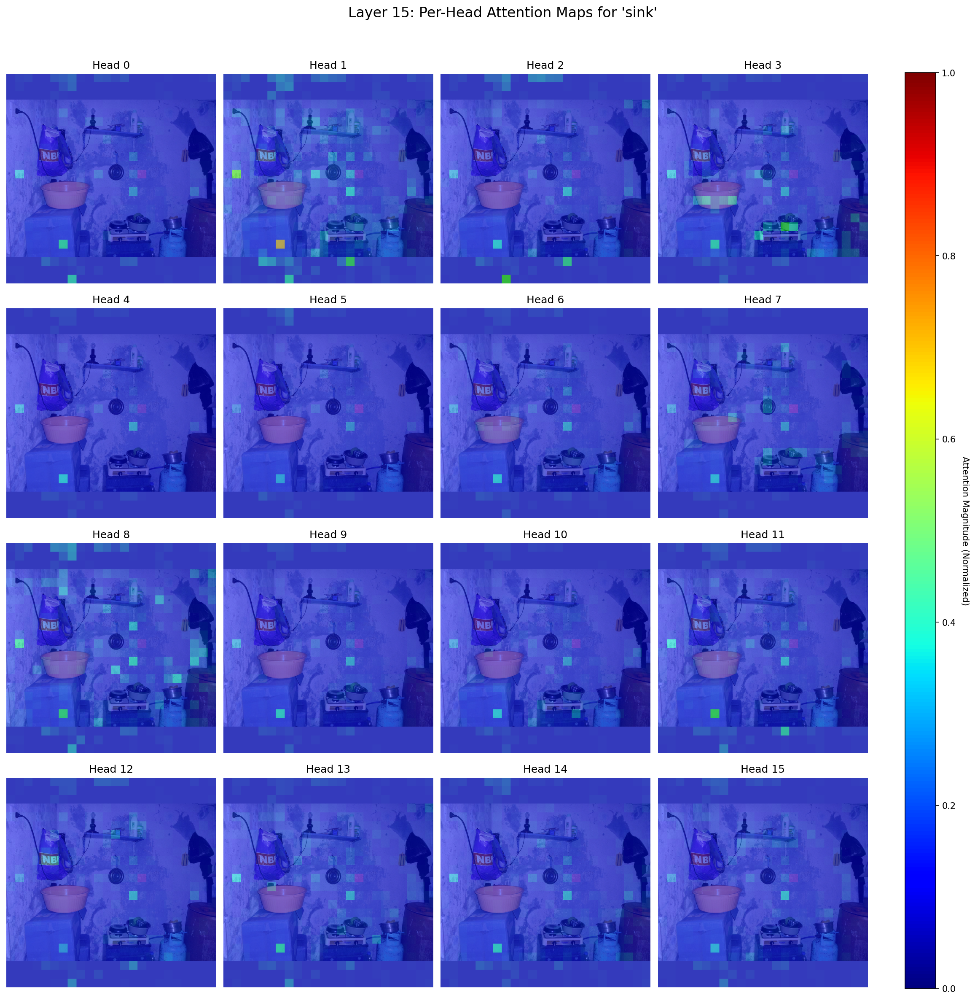

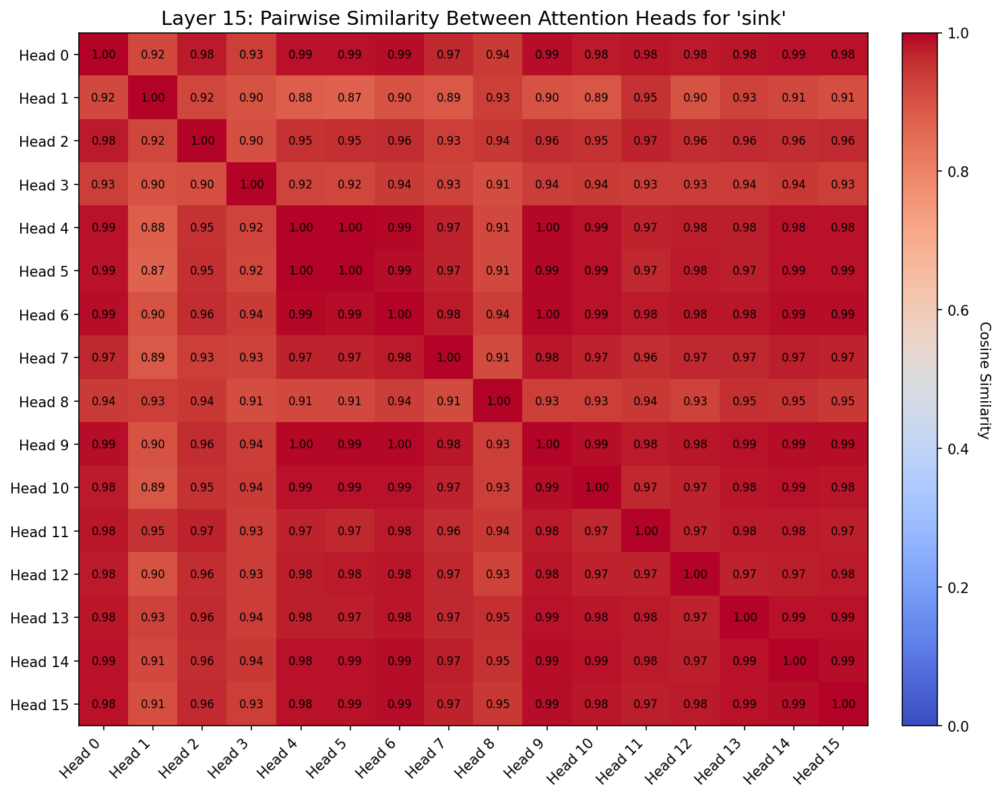


LAYER 20: PAIRWISE COSINE SIMILARITY BETWEEN ATTENTION HEADS
     Head 0  Head 1  Head 2  Head 3  Head 4  Head 5  Head 6  Head 7  Head 8  Head 9  Head10  Head11  Head12  Head13  Head14  Head15  
-------------------------------------------------------------------------------------------------------------------------------------
Head 0  1.000   0.847   0.954   0.975   0.972   0.969   0.972   0.958   0.964   0.951   0.942   0.953   0.873   0.965   0.969   0.968  
Head 1  0.847   1.000   0.914   0.874   0.875   0.882   0.843   0.841   0.867   0.914   0.925   0.896   0.931   0.816   0.883   0.844  
Head 2  0.954   0.914   1.000   0.976   0.963   0.964   0.954   0.953   0.949   0.962   0.967   0.960   0.920   0.942   0.969   0.958  
Head 3  0.975   0.874   0.976   1.000   0.971   0.969   0.975   0.965   0.955   0.951   0.966   0.957   0.892   0.973   0.980   0.979  
Head 4  0.972   0.875   0.963   0.971   1.000   0.982   0.986   0.982   0.993   0.974   0.959   0.983   0.882   0.977   0.981 

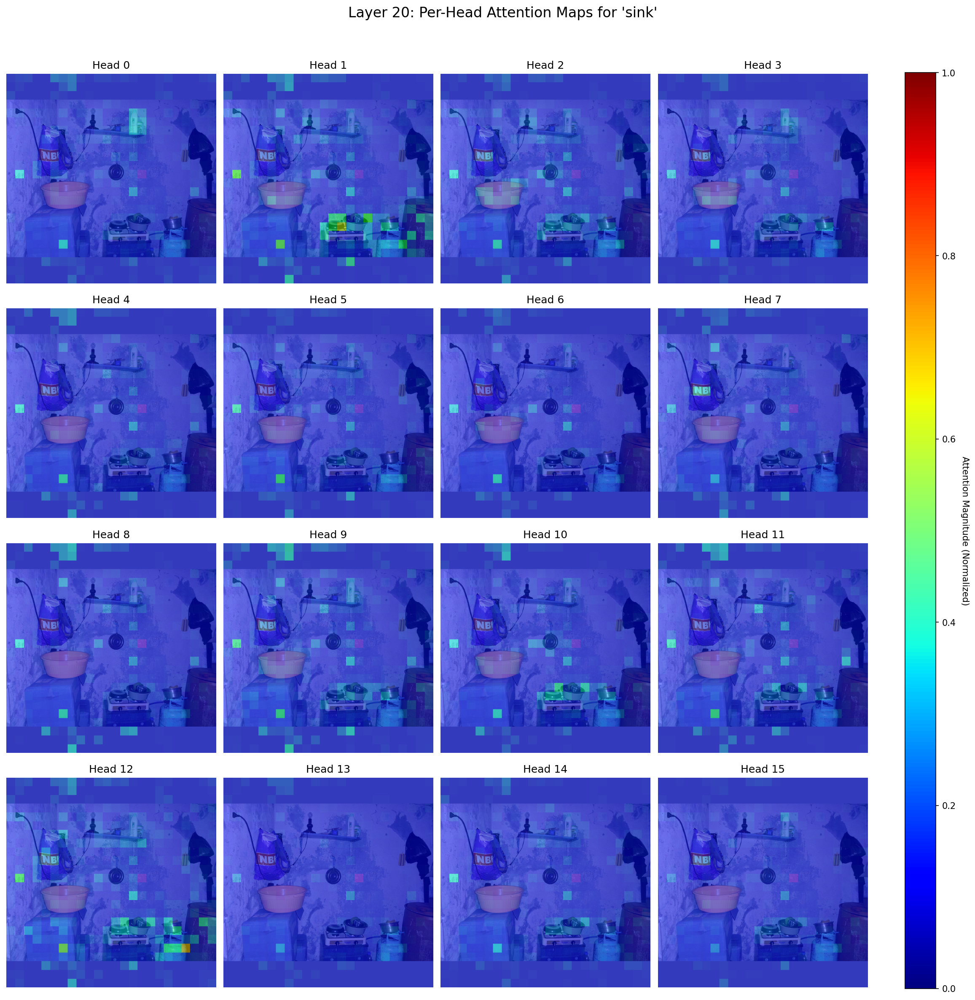

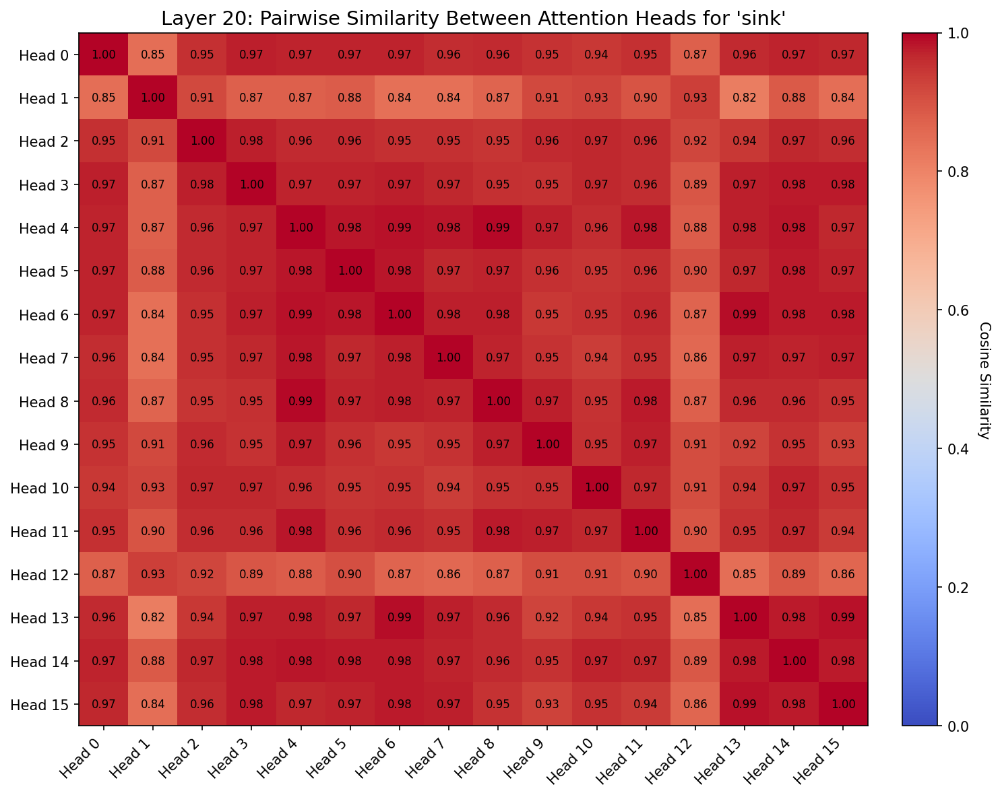


CROSS-LAYER SIMILARITY DISTRIBUTION ANALYSIS


/tmp/ipykernel_1385439/284829602.py:228: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(distributions, labels=[f"L{idx}" for idx in layer_indices],


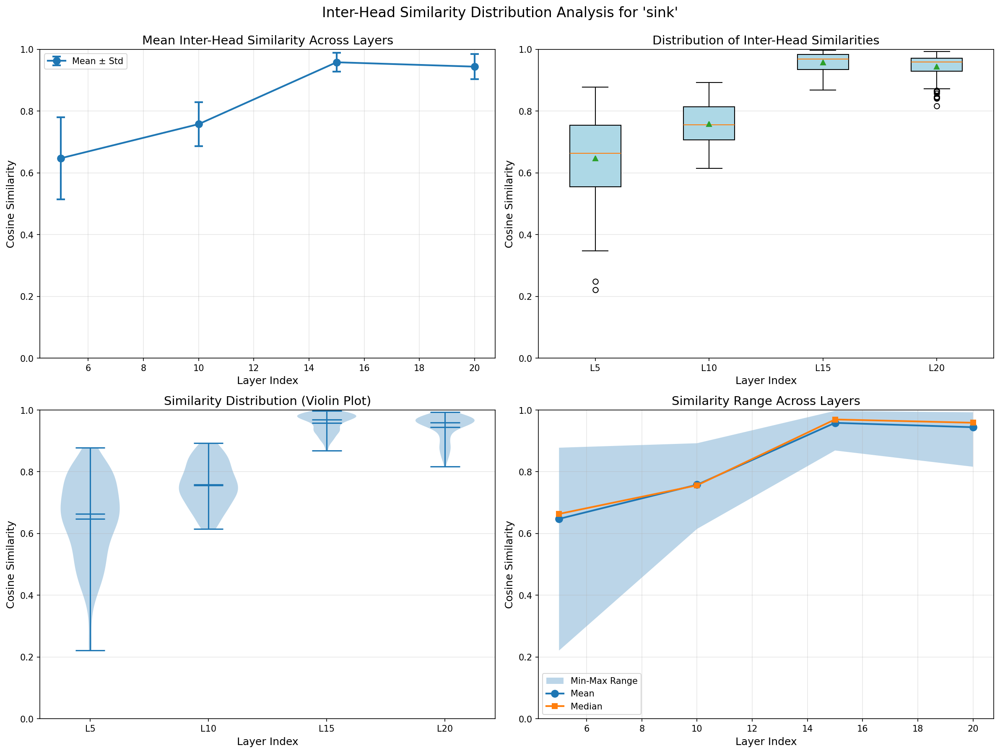

In [ ]:
# ==========================================
# MODIFIED CELL: Per-Head Attention Maps for Specific Layers
# ==========================================
import re
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import torch.nn.functional as F
from sklearn.metrics.pairwise import cosine_similarity

# user configuration
target_word = "sink"
nth_occurrence = 1
layer_indices = [5,10,15,20]  # specify which layers to visualize
# ==========================================

# print number of layers in vision tower
num_layers = len(model.get_vision_tower().image_attentions)
print(f"Total number of layers in Vision Tower: {num_layers}")
print(f"Visualizing layers: {layer_indices}\n")

# find the target token
full_sequence = outputs["sequences"][0]
generated_tokens = full_sequence
full_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)

matches = list(re.finditer(re.escape(target_word), full_text, re.IGNORECASE))

if len(matches) < nth_occurrence:
    print(f"Error: The word '{target_word}' was not found {nth_occurrence} times in the output.")
    print(f"Full generated text: '{full_text}'")
else:
    char_start_idx = matches[nth_occurrence - 1].start()
    
    # map character index to token index
    target_token_relative_idx = -1
    for i in range(len(generated_tokens)):
        text_chunk = tokenizer.decode(generated_tokens[:i+1], skip_special_tokens=True)
        if len(text_chunk) > char_start_idx:
            target_token_relative_idx = i
            break

    if target_token_relative_idx != -1:
        target_token_global_ind = output_token_start + target_token_relative_idx
        
        print(f"Visualizing per-head attention for word: '{target_word}' (Occurrence: {nth_occurrence})")
        print(f"Mapped to token: '{tokenizer.decode(generated_tokens[target_token_relative_idx])}'")

        # get per-head vision attention for specific layers
        def get_vit_attention_per_head_specific_layers(attn, layer_indices):
            # returns dict mapping layer_idx to attention tensor [num_heads, tokens, tokens]
            layer_head_attns = {}
            for idx in layer_indices:
                layer = attn[idx]
                layer_attn = layer.squeeze(0)  # [num_heads, seq_len, seq_len]
                vecs = layer_attn[:, 1:, 1:].cpu()  # remove cls token
                vecs = vecs / vecs.sum(-1, keepdim=True)  # normalize per head
                layer_head_attns[idx] = vecs
            return layer_head_attns
        
        # get per-head vision attention for specified layers
        layer_head_attentions = get_vit_attention_per_head_specific_layers(
            model.get_vision_tower().image_attentions,
            layer_indices
        )
        
        # get llm attention to vision tokens
        attn_weights_over_vis_tokens = llm_attn_matrix[target_token_global_ind][vision_token_start:vision_token_end]
        attn_weights_over_vis_tokens = attn_weights_over_vis_tokens / attn_weights_over_vis_tokens.sum()
        
        # store similarity statistics for cross-layer analysis
        layer_similarity_stats = {}
        layer_similarity_distributions = {}
        
        # process each layer
        for layer_idx in layer_indices:
            vis_attn_matrix_per_head = layer_head_attentions[layer_idx]
            num_heads = vis_attn_matrix_per_head.shape[0]
            
            # compute attention map for each head in this layer
            attention_maps = []
            for head_idx in range(num_heads):
                attn_over_image = []
                for weight, vis_attn in zip(attn_weights_over_vis_tokens, vis_attn_matrix_per_head[head_idx]):
                    vis_attn = vis_attn.reshape(grid_size, grid_size)
                    attn_over_image.append(vis_attn * weight)
                
                attn_over_image = torch.stack(attn_over_image).sum(dim=0)
                attn_over_image = attn_over_image / attn_over_image.max()
                
                # resize to original image size
                attn_over_image = F.interpolate(
                    attn_over_image.unsqueeze(0).unsqueeze(0), 
                    size=image.size, 
                    mode='nearest', 
                ).squeeze()
                
                attention_maps.append(attn_over_image)
            
            # compute pairwise cosine similarity between attention maps
            attention_maps_flat = [attn_map.flatten().numpy() for attn_map in attention_maps]
            attention_maps_array = np.array(attention_maps_flat)
            similarity_matrix = cosine_similarity(attention_maps_array)
            
            # extract upper triangular values (excluding diagonal)
            upper_tri_indices = np.triu_indices(num_heads, k=1)
            pairwise_sims = similarity_matrix[upper_tri_indices]
            
            # store statistics
            layer_similarity_stats[layer_idx] = {
                'mean': np.mean(pairwise_sims),
                'std': np.std(pairwise_sims),
                'min': np.min(pairwise_sims),
                'max': np.max(pairwise_sims),
                'median': np.median(pairwise_sims)
            }
            layer_similarity_distributions[layer_idx] = pairwise_sims
            
            # print similarity matrix for this layer
            print("\n" + "="*80)
            print(f"LAYER {layer_idx}: PAIRWISE COSINE SIMILARITY BETWEEN ATTENTION HEADS")
            print("="*80)
            
            # print header
            header = "     " + "".join([f"Head{i:2d}  " for i in range(num_heads)])
            print(header)
            print("-" * len(header))
            
            # print similarity values
            for i in range(num_heads):
                row_str = f"Head{i:2d} "
                for j in range(num_heads):
                    row_str += f"{similarity_matrix[i, j]:6.3f}  "
                print(row_str)
            
            # print statistics
            print("\nStatistics (excluding diagonal):")
            print(f"  Mean: {layer_similarity_stats[layer_idx]['mean']:.4f}")
            print(f"  Std:  {layer_similarity_stats[layer_idx]['std']:.4f}")
            print(f"  Min:  {layer_similarity_stats[layer_idx]['min']:.4f}")
            print(f"  Max:  {layer_similarity_stats[layer_idx]['max']:.4f}")
            print(f"  Median: {layer_similarity_stats[layer_idx]['median']:.4f}")
            print("="*80 + "\n")
            
            # plot all heads in a grid for this layer
            cols = 4
            rows = (num_heads + cols - 1) // cols  # ceiling division
            
            fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 4), dpi=150)
            axes = axes.flatten() if num_heads > 1 else [axes]
            
            np_img = np.array(image)[:, :, ::-1]
            
            for head_idx, (ax, attn_map) in enumerate(zip(axes, attention_maps)):
                # create overlay
                img_with_attn, _ = show_mask_on_image(np_img, attn_map.numpy())
                
                # display
                ax.imshow(img_with_attn)
                ax.set_title(f"Head {head_idx}")
                ax.axis("off")
            
            # hide unused subplots
            for idx in range(num_heads, len(axes)):
                axes[idx].axis("off")
            
            # adjust layout before adding colorbar
            fig.suptitle(f"Layer {layer_idx}: Per-Head Attention Maps for '{target_word}'", fontsize=16)
            plt.tight_layout(rect=[0, 0, 0.95, 0.96])  # leave space for colorbar on right and title on top
            
            # add single colorbar for all subplots
            sm = cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=0, vmax=1))
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=axes.tolist(), fraction=0.046, pad=0.04, aspect=30)
            cbar.set_label('Attention Magnitude (Normalized)', rotation=270, labelpad=15)
            
            plt.show()
            
            # plot similarity heatmap for this layer
            fig_sim, ax_sim = plt.subplots(figsize=(10, 8), dpi=150)
            im = ax_sim.imshow(similarity_matrix, cmap='coolwarm', vmin=0, vmax=1, aspect='auto')
            
            # add colorbar
            cbar_sim = fig_sim.colorbar(im, ax=ax_sim, fraction=0.046, pad=0.04)
            cbar_sim.set_label('Cosine Similarity', rotation=270, labelpad=15)
            
            # set ticks and labels
            ax_sim.set_xticks(range(num_heads))
            ax_sim.set_yticks(range(num_heads))
            ax_sim.set_xticklabels([f"Head {i}" for i in range(num_heads)], rotation=45, ha='right')
            ax_sim.set_yticklabels([f"Head {i}" for i in range(num_heads)])
            
            # add text annotations
            for i in range(num_heads):
                for j in range(num_heads):
                    text = ax_sim.text(j, i, f'{similarity_matrix[i, j]:.2f}',
                                     ha="center", va="center", color="black", fontsize=8)
            
            ax_sim.set_title(f"Layer {layer_idx}: Pairwise Similarity Between Attention Heads for '{target_word}'", fontsize=14)
            plt.tight_layout()
            plt.show()
        
        # ==========================================
        # cross-layer similarity distribution analysis
        # ==========================================
        print("\n" + "="*80)
        print("CROSS-LAYER SIMILARITY DISTRIBUTION ANALYSIS")
        print("="*80)
        
        # create subplots for distribution analysis
        fig_dist, axes_dist = plt.subplots(2, 2, figsize=(16, 12), dpi=150)
        
        # 1. line plot with error bars showing mean and std
        ax1 = axes_dist[0, 0]
        means = [layer_similarity_stats[idx]['mean'] for idx in layer_indices]
        stds = [layer_similarity_stats[idx]['std'] for idx in layer_indices]
        ax1.errorbar(layer_indices, means, yerr=stds, marker='o', linewidth=2, 
                     markersize=8, capsize=5, capthick=2, label='Mean ± Std')
        ax1.set_xlabel('Layer Index', fontsize=12)
        ax1.set_ylabel('Cosine Similarity', fontsize=12)
        ax1.set_title('Mean Inter-Head Similarity Across Layers', fontsize=14)
        ax1.grid(True, alpha=0.3)
        ax1.legend()
        ax1.set_ylim([0, 1])
        
        # 2. box plot showing distribution
        ax2 = axes_dist[0, 1]
        distributions = [layer_similarity_distributions[idx] for idx in layer_indices]
        bp = ax2.boxplot(distributions, labels=[f"L{idx}" for idx in layer_indices],
                         patch_artist=True, showmeans=True)
        # color boxes
        for patch in bp['boxes']:
            patch.set_facecolor('lightblue')
        ax2.set_xlabel('Layer Index', fontsize=12)
        ax2.set_ylabel('Cosine Similarity', fontsize=12)
        ax2.set_title('Distribution of Inter-Head Similarities', fontsize=14)
        ax2.grid(True, alpha=0.3, axis='y')
        ax2.set_ylim([0, 1])
        
        # 3. violin plot for better distribution visualization
        ax3 = axes_dist[1, 0]
        parts = ax3.violinplot(distributions, positions=range(len(layer_indices)), 
                               showmeans=True, showmedians=True)
        ax3.set_xticks(range(len(layer_indices)))
        ax3.set_xticklabels([f"L{idx}" for idx in layer_indices])
        ax3.set_xlabel('Layer Index', fontsize=12)
        ax3.set_ylabel('Cosine Similarity', fontsize=12)
        ax3.set_title('Similarity Distribution (Violin Plot)', fontsize=14)
        ax3.grid(True, alpha=0.3, axis='y')
        ax3.set_ylim([0, 1])
        
        # 4. min/max range plot
        ax4 = axes_dist[1, 1]
        mins = [layer_similarity_stats[idx]['min'] for idx in layer_indices]
        maxs = [layer_similarity_stats[idx]['max'] for idx in layer_indices]
        medians = [layer_similarity_stats[idx]['median'] for idx in layer_indices]
        ax4.fill_between(layer_indices, mins, maxs, alpha=0.3, label='Min-Max Range')
        ax4.plot(layer_indices, means, marker='o', linewidth=2, markersize=8, label='Mean')
        ax4.plot(layer_indices, medians, marker='s', linewidth=2, markersize=6, label='Median')
        ax4.set_xlabel('Layer Index', fontsize=12)
        ax4.set_ylabel('Cosine Similarity', fontsize=12)
        ax4.set_title('Similarity Range Across Layers', fontsize=14)
        ax4.grid(True, alpha=0.3)
        ax4.legend()
        ax4.set_ylim([0, 1])
        
        fig_dist.suptitle(f"Inter-Head Similarity Distribution Analysis for '{target_word}'", 
                         fontsize=16, y=0.995)
        plt.tight_layout()
        plt.show()
        
    else:
        print("Error: Could not map the word to a specific token.")

Visualizing layer-specific attention for word: 'vase' (Occurrence: 1)
Mapped to token: 'v'
Layers: [-4, -3, -2]


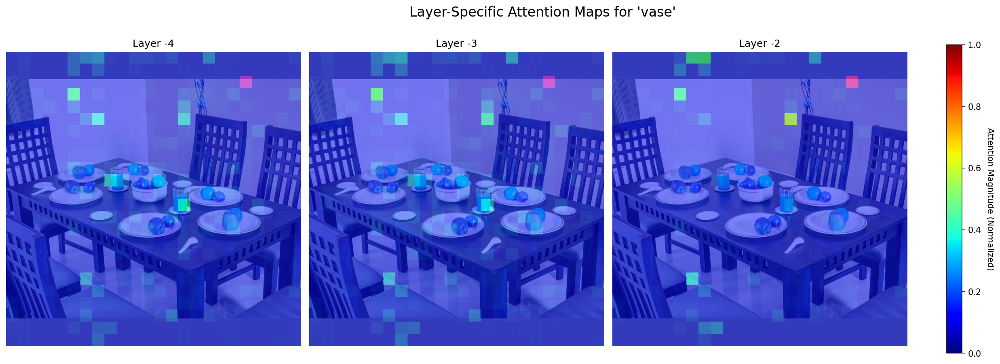

In [ ]:
# ==========================================
# SECOND CELL: Specific Layer Attention Maps
# ==========================================
import re
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import torch.nn.functional as F

# user configuration
target_word = "vase"
nth_occurrence = 1
layer_indices = [-4, -3, -2]  # specify which layers to visualize
# ==========================================

# find the target token
full_sequence = outputs["sequences"][0]
generated_tokens = full_sequence
full_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)

matches = list(re.finditer(re.escape(target_word), full_text, re.IGNORECASE))

if len(matches) < nth_occurrence:
    print(f"Error: The word '{target_word}' was not found {nth_occurrence} times in the output.")
    print(f"Full generated text: '{full_text}'")
else:
    char_start_idx = matches[nth_occurrence - 1].start()
    
    # map character index to token index
    target_token_relative_idx = -1
    for i in range(len(generated_tokens)):
        text_chunk = tokenizer.decode(generated_tokens[:i+1], skip_special_tokens=True)
        if len(text_chunk) > char_start_idx:
            target_token_relative_idx = i
            break

    if target_token_relative_idx != -1:
        target_token_global_ind = output_token_start + target_token_relative_idx
        
        print(f"Visualizing layer-specific attention for word: '{target_word}' (Occurrence: {nth_occurrence})")
        print(f"Mapped to token: '{tokenizer.decode(generated_tokens[target_token_relative_idx])}'")
        print(f"Layers: {layer_indices}")

        # get attention for specific layers only
        def get_vit_attention_specific_layers(attn, layer_indices):
            # returns list of attention matrices, one per specified layer
            layer_attns = []
            for idx in layer_indices:
                layer = attn[idx]
                layer_attn = layer.squeeze(0)  # [num_heads, seq_len, seq_len]
                attns_per_head = layer_attn.mean(dim=0)  # average across heads
                vec = attns_per_head[1:, 1:].cpu()  # remove cls token
                vec = vec / vec.sum(-1, keepdim=True)  # normalize
                layer_attns.append(vec)
            return layer_attns
        
        # get vision attention for specified layers
        vis_attn_matrices = get_vit_attention_specific_layers(
            model.get_vision_tower().image_attentions,
            layer_indices
        )
        
        # get llm attention to vision tokens
        attn_weights_over_vis_tokens = llm_attn_matrix[target_token_global_ind][vision_token_start:vision_token_end]
        attn_weights_over_vis_tokens = attn_weights_over_vis_tokens / attn_weights_over_vis_tokens.sum()
        
        # compute attention map for each layer
        attention_maps = []
        for layer_idx, vis_attn_matrix_layer in zip(layer_indices, vis_attn_matrices):
            attn_over_image = []
            for weight, vis_attn in zip(attn_weights_over_vis_tokens, vis_attn_matrix_layer):
                vis_attn = vis_attn.reshape(grid_size, grid_size)
                attn_over_image.append(vis_attn * weight)
            
            attn_over_image = torch.stack(attn_over_image).sum(dim=0)
            attn_over_image = attn_over_image / attn_over_image.max()
            
            # resize to original image size
            attn_over_image = F.interpolate(
                attn_over_image.unsqueeze(0).unsqueeze(0), 
                size=image.size, 
                mode='nearest', 
            ).squeeze()
            
            attention_maps.append((layer_idx, attn_over_image))
        
        # plot all layers in a row
        num_layers = len(layer_indices)
        fig, axes = plt.subplots(1, num_layers, figsize=(6 * num_layers, 6), dpi=150)
        axes = axes.flatten() if num_layers > 1 else [axes]
        
        np_img = np.array(image)[:, :, ::-1]
        
        for ax, (layer_idx, attn_map) in zip(axes, attention_maps):
            # create overlay
            img_with_attn, _ = show_mask_on_image(np_img, attn_map.numpy())
            
            # display
            ax.imshow(img_with_attn)
            ax.set_title(f"Layer {layer_idx}")
            ax.axis("off")
        
        # adjust layout before adding colorbar
        fig.suptitle(f"Layer-Specific Attention Maps for '{target_word}'", fontsize=16)
        plt.tight_layout(rect=[0, 0, 0.92, 0.96])  # leave space for colorbar on right and title on top
        
        # add colorbar
        sm = cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=0, vmax=1))
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=axes.tolist(), fraction=0.046, pad=0.04)
        cbar.set_label('Attention Magnitude (Normalized)', rotation=270, labelpad=15)
        
        plt.show()
    else:
        print("Error: Could not map the word to a specific token.")

Total number of layers in Vision Tower: 24

Token 1: 'sink' -> 'sink'
Token 2: 'bowl' -> 'bow'

LAYER-WISE COSINE SIMILARITY: 'sink' vs 'bowl'
   Layer |   Similarity
--------------------------------------------------------------------------------
       0 |       0.9826
       1 |       0.9256
       2 |       0.8385
       3 |       0.8650
       4 |       0.9324
       5 |       0.9107
       6 |       0.8047
       7 |       0.8859
       8 |       0.8626
       9 |       0.8535
      10 |       0.8650
      11 |       0.9294
      12 |       0.9837
      13 |       0.9945
      14 |       0.9902
      15 |       0.9981
      16 |       0.9969
      17 |       0.9993
      18 |       0.9985
      19 |       0.9986
      20 |       0.9979
      21 |       0.9986
      22 |       0.9991
      23 |       0.9984



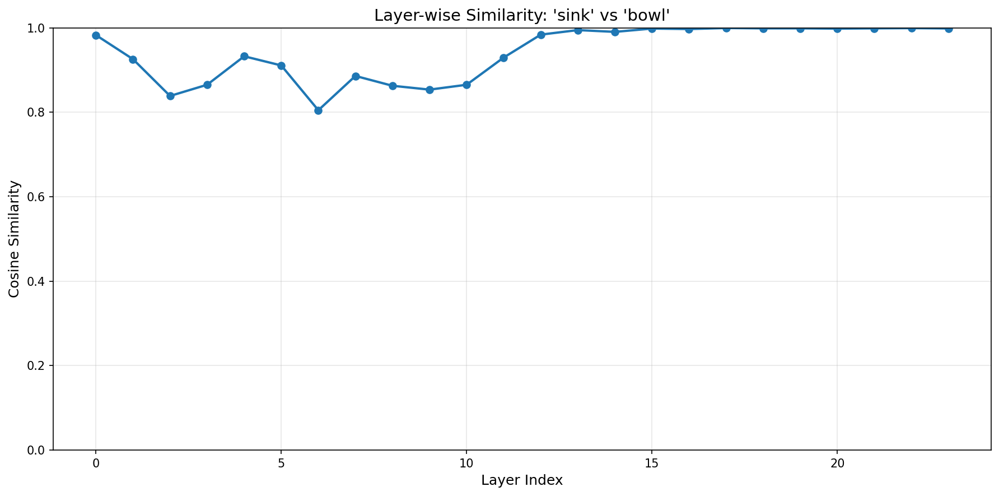

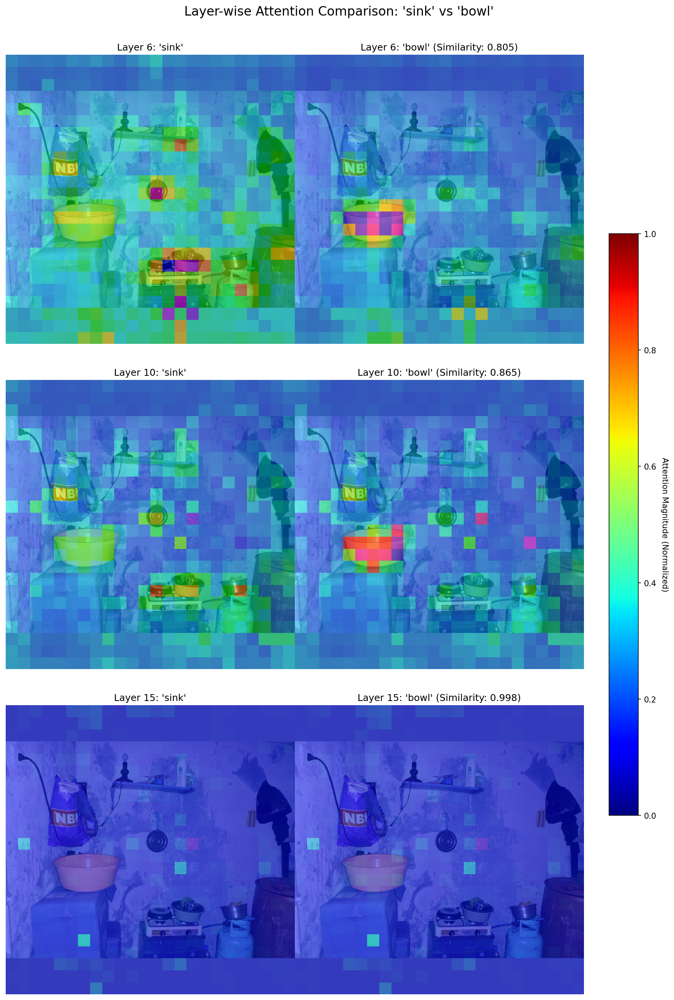

In [ ]:
# ==========================================
# NEW CELL: Layer-wise Similarity Between Two Tokens
# ==========================================
import re
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import torch.nn.functional as F
from sklearn.metrics.pairwise import cosine_similarity

# user configuration
target_word_1 = "sink"
target_word_2 = "bowl"
nth_occurrence_1 = 1
nth_occurrence_2 = 1
layers_to_plot = [6, 10, 15]  # specific layers to visualize side-by-side
# ==========================================

# print number of layers
num_layers = len(model.get_vision_tower().image_attentions)
print(f"Total number of layers in Vision Tower: {num_layers}\n")

# find both target tokens
full_sequence = outputs["sequences"][0]
generated_tokens = full_sequence
full_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)

# find token 1
matches_1 = list(re.finditer(re.escape(target_word_1), full_text, re.IGNORECASE))
if len(matches_1) < nth_occurrence_1:
    print(f"Error: The word '{target_word_1}' was not found {nth_occurrence_1} times in the output.")
    target_token_1 = None
else:
    char_start_idx_1 = matches_1[nth_occurrence_1 - 1].start()
    target_token_relative_idx_1 = -1
    for i in range(len(generated_tokens)):
        text_chunk = tokenizer.decode(generated_tokens[:i+1], skip_special_tokens=True)
        if len(text_chunk) > char_start_idx_1:
            target_token_relative_idx_1 = i
            break
    target_token_1 = output_token_start + target_token_relative_idx_1 if target_token_relative_idx_1 != -1 else None

# find token 2
matches_2 = list(re.finditer(re.escape(target_word_2), full_text, re.IGNORECASE))
if len(matches_2) < nth_occurrence_2:
    print(f"Error: The word '{target_word_2}' was not found {nth_occurrence_2} times in the output.")
    target_token_2 = None
else:
    char_start_idx_2 = matches_2[nth_occurrence_2 - 1].start()
    target_token_relative_idx_2 = -1
    for i in range(len(generated_tokens)):
        text_chunk = tokenizer.decode(generated_tokens[:i+1], skip_special_tokens=True)
        if len(text_chunk) > char_start_idx_2:
            target_token_relative_idx_2 = i
            break
    target_token_2 = output_token_start + target_token_relative_idx_2 if target_token_relative_idx_2 != -1 else None

if target_token_1 is not None and target_token_2 is not None:
    print(f"Token 1: '{target_word_1}' -> '{tokenizer.decode(generated_tokens[target_token_relative_idx_1])}'")
    print(f"Token 2: '{target_word_2}' -> '{tokenizer.decode(generated_tokens[target_token_relative_idx_2])}'")
    print()
    
    # get attention for both tokens from llm
    attn_weights_token_1 = llm_attn_matrix[target_token_1][vision_token_start:vision_token_end]
    attn_weights_token_1 = attn_weights_token_1 / attn_weights_token_1.sum()
    
    attn_weights_token_2 = llm_attn_matrix[target_token_2][vision_token_start:vision_token_end]
    attn_weights_token_2 = attn_weights_token_2 / attn_weights_token_2.sum()
    
    # compute layer-wise attention maps for both tokens
    def get_layer_attention_map(layer_idx, attn_weights_over_vis_tokens):
        # get vision attention for this layer (averaged across heads)
        layer = model.get_vision_tower().image_attentions[layer_idx]
        layer_attn = layer.squeeze(0)  # [num_heads, seq_len, seq_len]
        attns_per_head = layer_attn.mean(dim=0)  # average across heads
        vec = attns_per_head[1:, 1:].cpu()  # remove cls token
        vec = vec / vec.sum(-1, keepdim=True)  # normalize
        
        # compute weighted attention over image
        attn_over_image = []
        for weight, vis_attn in zip(attn_weights_over_vis_tokens, vec):
            vis_attn = vis_attn.reshape(grid_size, grid_size)
            attn_over_image.append(vis_attn * weight)
        
        attn_over_image = torch.stack(attn_over_image).sum(dim=0)
        attn_over_image = attn_over_image / attn_over_image.max()
        
        # resize to original image size
        attn_over_image = F.interpolate(
            attn_over_image.unsqueeze(0).unsqueeze(0), 
            size=image.size, 
            mode='nearest', 
        ).squeeze()
        
        return attn_over_image
    
    # compute similarity for all layers
    similarities = []
    token1_maps = []
    token2_maps = []
    
    for layer_idx in range(num_layers):
        # get attention maps for both tokens
        map1 = get_layer_attention_map(layer_idx, attn_weights_token_1)
        map2 = get_layer_attention_map(layer_idx, attn_weights_token_2)
        
        token1_maps.append(map1)
        token2_maps.append(map2)
        
        # compute cosine similarity
        map1_flat = map1.flatten().numpy().reshape(1, -1)
        map2_flat = map2.flatten().numpy().reshape(1, -1)
        sim = cosine_similarity(map1_flat, map2_flat)[0, 0]
        similarities.append(sim)
    
    # print layer-wise similarities
    print("="*80)
    print(f"LAYER-WISE COSINE SIMILARITY: '{target_word_1}' vs '{target_word_2}'")
    print("="*80)
    print(f"{'Layer':>8} | {'Similarity':>12}")
    print("-" * 80)
    for layer_idx, sim in enumerate(similarities):
        print(f"{layer_idx:8d} | {sim:12.4f}")
    print("="*80 + "\n")
    
    # plot similarity curve
    fig_curve, ax_curve = plt.subplots(figsize=(12, 6), dpi=150)
    ax_curve.plot(range(num_layers), similarities, marker='o', linewidth=2, markersize=6)
    ax_curve.set_xlabel('Layer Index', fontsize=12)
    ax_curve.set_ylabel('Cosine Similarity', fontsize=12)
    ax_curve.set_title(f"Layer-wise Similarity: '{target_word_1}' vs '{target_word_2}'", fontsize=14)
    ax_curve.grid(True, alpha=0.3)
    ax_curve.set_ylim([0, 1])
    plt.tight_layout()
    plt.show()
    
    # plot side-by-side attention maps for specified layers
    num_plot_layers = len(layers_to_plot)
    fig, axes = plt.subplots(num_plot_layers, 2, figsize=(12, 6 * num_plot_layers), dpi=150)
    
    # ensure axes is 2d array
    if num_plot_layers == 1:
        axes = axes.reshape(1, -1)
    
    np_img = np.array(image)[:, :, ::-1]
    
    for idx, layer_idx in enumerate(layers_to_plot):
        if layer_idx >= num_layers:
            print(f"Warning: Layer {layer_idx} exceeds total layers ({num_layers}). Skipping.")
            continue
        
        # plot token 1 attention map
        map1 = token1_maps[layer_idx]
        img_with_attn_1, _ = show_mask_on_image(np_img, map1.numpy())
        axes[idx, 0].imshow(img_with_attn_1)
        axes[idx, 0].set_title(f"Layer {layer_idx}: '{target_word_1}'", fontsize=12)
        axes[idx, 0].axis("off")
        
        # plot token 2 attention map
        map2 = token2_maps[layer_idx]
        img_with_attn_2, _ = show_mask_on_image(np_img, map2.numpy())
        axes[idx, 1].imshow(img_with_attn_2)
        axes[idx, 1].set_title(f"Layer {layer_idx}: '{target_word_2}' (Similarity: {similarities[layer_idx]:.3f})", fontsize=12)
        axes[idx, 1].axis("off")
    
    # add colorbar
    sm = cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    
    fig.suptitle(f"Layer-wise Attention Comparison: '{target_word_1}' vs '{target_word_2}'", fontsize=16)
    plt.tight_layout(rect=[0, 0, 0.95, 0.98])
    
    cbar = fig.colorbar(sm, ax=axes, fraction=0.046, pad=0.04)
    cbar.set_label('Attention Magnitude (Normalized)', rotation=270, labelpad=15)
    
    plt.show()
    
else:
    print("Error: Could not find one or both target tokens.")